# Prévoir la production minière de la Guinée jusqu'en 2035 (machine learning)

**Question :** si les tendances observées se prolongent, combien la Guinée produira-t-elle de bauxite et d'or en 2035, et que pèseront ses exportations minières avec Simandou ?

**Méthode :**
1. Regarder la série avant de choisir un modèle.
2. Comparer deux régressions linéaires (scikit-learn).
3. **Tester** chaque modèle sur des années qu'il n'a pas vues.
4. Prévoir jusqu'en 2035 avec un **intervalle de prédiction à 95 %**.
5. Assembler bauxite, or et fer en une estimation des exportations de 2035.
6. **Comparer** la Guinée aux autres producteurs mondiaux, aujourd'hui et en 2035.

**Données :**
- `data/bauxite_production_longue.csv` : 2000-2024, USGS Minerals Yearbook (2000-2018) puis Ministère des Mines (2019-2024).
- `data/or_production_longue.csv` : or industriel 2008-2024, mêmes sources.
- `data/prix_reference.csv` : prix utilisés pour passer des volumes aux dollars.
- `data/bauxite_monde.csv` : production de la Guinée, de l'Australie, de la Chine et du monde, 2000-2025 (USGS, tonnes sèches), pour comparer.

Code : `src/prevision.py` (modèles), `sql/05_*.sql` (chargement des séries).

In [1]:
import sys
sys.path.append("..")

from src.requetes import requete
from src.prevision import entrainer, tester, prevoir, synthese, part_prevue
from src.graphiques import (graphique_deux_modeles, graphique_prevision, graphique_synthese,
                            graphique_bauxite_pays, graphique_part_guinee, BAUXITE, OR)

## 1. Regarder les données d'abord : une rupture en 2016

Droite 2000-2024 : +4.3 Mt par an, R² = 0.68
Droite 2016-2024 : +12.4 Mt par an, R² = 0.98


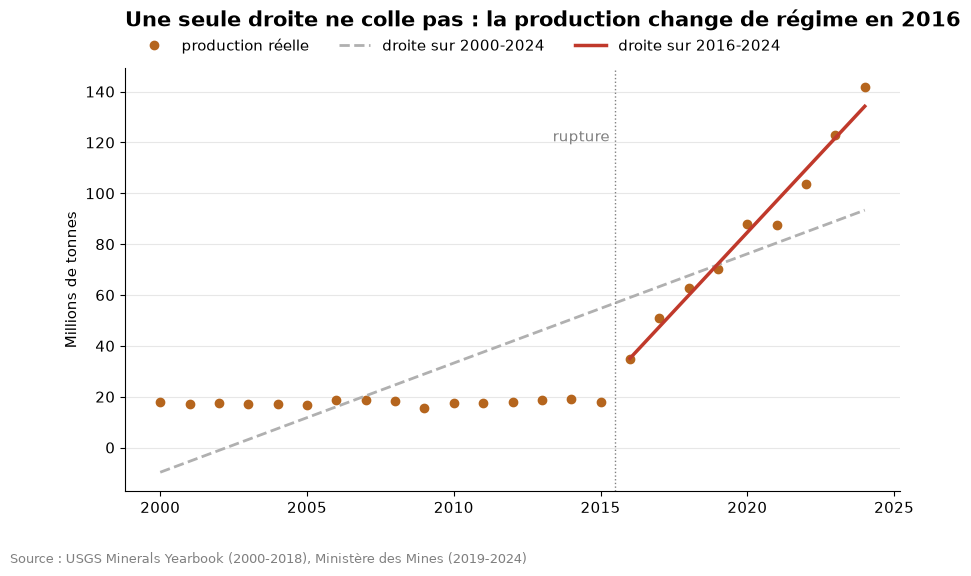

In [2]:
bauxite = requete("05_bauxite_serie").df()
modele_long = entrainer(bauxite, debut=2000, fin=2024)
modele_court = entrainer(bauxite, debut=2016, fin=2024)
print(f"Droite 2000-2024 : +{modele_long.coef_[0]:.1f} Mt par an, R² = {modele_long.score(bauxite[['annee']], bauxite['valeur']):.2f}")
recent = bauxite[bauxite["annee"] >= 2016]
print(f"Droite 2016-2024 : +{modele_court.coef_[0]:.1f} Mt par an, R² = {modele_court.score(recent[['annee']], recent['valeur']):.2f}")
graphique_deux_modeles(bauxite, modele_long, modele_court, debut_court=2016)

**Constat :** de 2000 à 2015, la production reste plate, autour de 17-19 Mt. En 2016, elle double, avec l'arrivée de SMB et des sociétés chinoises (étape 2), puis elle augmente d'environ **12 Mt par an**.

Une seule droite sur 2000-2024 passe « entre » les deux régimes (R² = 0,68). La droite sur 2016-2024 suit beaucoup mieux les points (R² = 0,98). Le R² mesure la part des variations expliquée par le modèle : 1 = parfait.

## 2. Tester honnêtement : on cache 2022-2024 aux modèles

In [3]:
for debut in (2000, 2016):
    test, erreur = tester(bauxite, debut=debut, fin_entrainement=2021)
    print(f"Modèle entraîné sur {debut}-2021 : erreur moyenne de {erreur:.1f} Mt")
    display(test.round(1))

Modèle entraîné sur 2000-2021 : erreur moyenne de 56.5 Mt


,annee,valeur,prevision,erreur_pct
22,2022,103.5,63.4,-38.8
23,2023,123.1,66.2,-46.2
24,2024,141.7,69.1,-51.3


Modèle entraîné sur 2016-2021 : erreur moyenne de 8.3 Mt


,annee,valeur,prevision,erreur_pct
22,2022,103.5,103.7,0.2
23,2023,123.1,114.6,-6.8
24,2024,141.7,125.5,-11.4


**Constat :** chaque modèle apprend sur les années jusqu'en 2021, puis prédit 2022, 2023 et 2024, qu'il n'a jamais vues.
- **Modèle 2000-2021 :** il se trompe de 39 à 51 % (erreur moyenne de 56 Mt). Il est inutilisable.
- **Modèle 2016-2021 :** il se trompe de 0 à 11 % (erreur moyenne de 8 Mt). C'est celui qu'on garde.

Même le bon modèle **sous-estime** les années récentes. La production n'augmente pas en ligne droite : elle **accélère**. Le chiffre de 2025 le confirme : environ 183 Mt exportées selon le ministère, contre environ 147 Mt prévues par le modèle. La prévision ci-dessous est donc plutôt **prudente**.

## 3. Prévision de la bauxite jusqu'en 2035

,annee,prevision,bas,haut
0,2025,146.6,130.2,163.0
1,2026,159.0,141.7,176.3
2,2027,171.4,153.0,189.8
3,2028,183.8,164.2,203.4
4,2029,196.2,175.4,217.0
5,2030,208.6,186.5,230.7
6,2031,221.0,197.5,244.4
7,2032,233.4,208.5,258.2
8,2033,245.8,219.5,272.0
9,2034,258.2,230.4,285.9


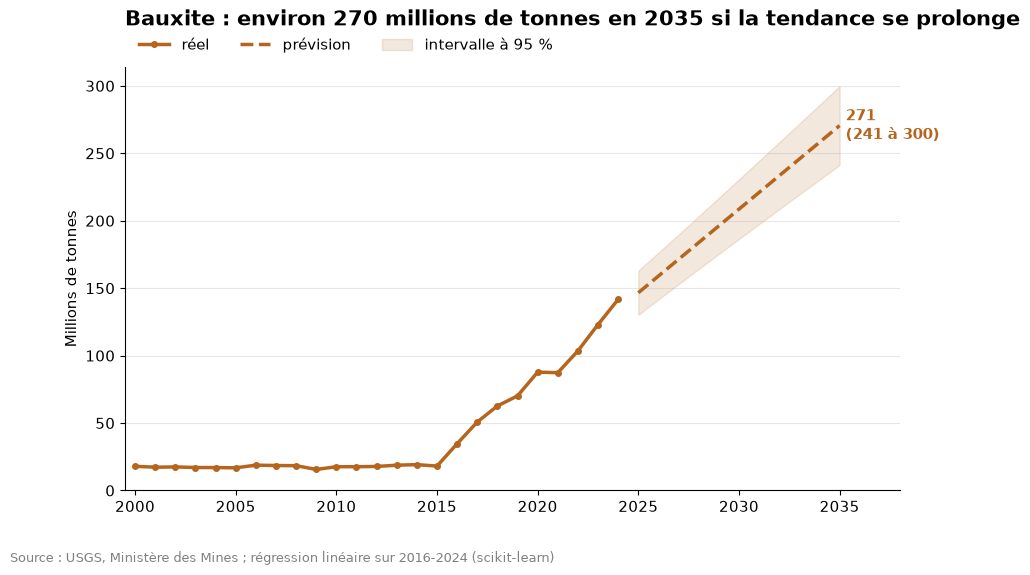

In [4]:
prevision_bauxite, _ = prevoir(bauxite, debut=2016, fin=2024, horizon=2035)
display(prevision_bauxite.round(1))
graphique_prevision(bauxite, prevision_bauxite,
                    titre="Bauxite : environ 270 millions de tonnes en 2035 si la tendance se prolonge",
                    unite="Millions de tonnes", couleur=BAUXITE,
                    source="USGS, Ministère des Mines ; régression linéaire sur 2016-2024 (scikit-learn)",
                    nom_fichier="prevision_bauxite.png")

**Conclusion :** si la tendance 2016-2024 se prolonge, la Guinée produirait environ **270 Mt de bauxite en 2035** (entre 241 et 300 Mt avec 95 % de confiance), soit presque deux fois plus qu'en 2024.

L'intervalle **s'élargit** avec le temps : plus on prévoit loin, plus l'incertitude est grande. Il ne couvre que l'incertitude statistique. Il ne couvre pas une rupture : une baisse de la demande chinoise, la saturation des mines ou une nouvelle politique de l'État.

## 4. Le même modèle sur l'or industriel

Erreur moyenne sur 2022-2024 : 4.7 t
Pente : +0.09 t par an


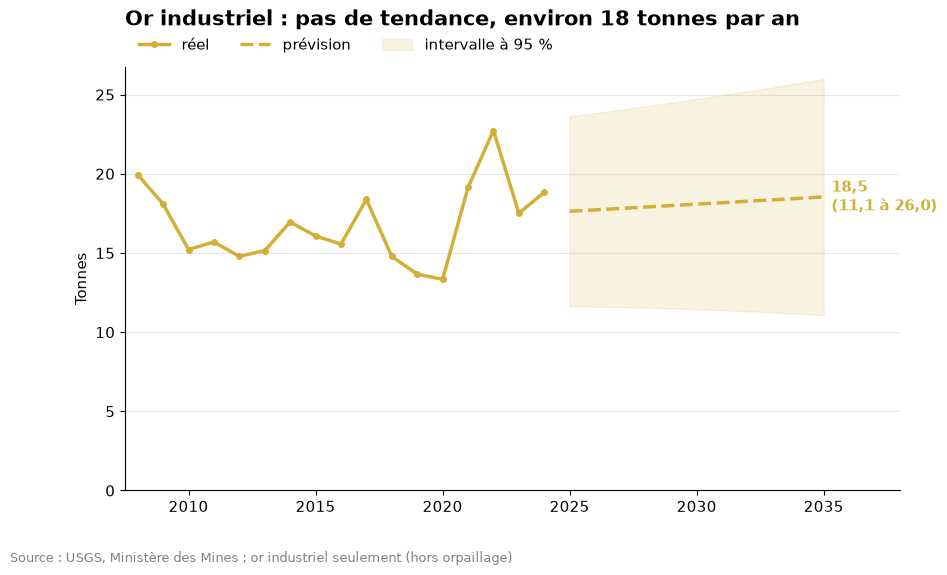

In [5]:
orr = requete("05_or_serie").df()
test, erreur = tester(orr, debut=2008, fin_entrainement=2021)
print(f"Erreur moyenne sur 2022-2024 : {erreur:.1f} t")
prevision_or, modele_or = prevoir(orr, debut=2008, fin=2024, horizon=2035)
print(f"Pente : {modele_or.coef_[0]:+.2f} t par an")
graphique_prevision(orr, prevision_or,
                    titre="Or industriel : pas de tendance, environ 18 tonnes par an",
                    unite="Tonnes", couleur=OR,
                    source="USGS, Ministère des Mines ; or industriel seulement (hors orpaillage)",
                    nom_fichier="prevision_or.png")

**Conclusion :** contrairement à la bauxite, l'or industriel **n'a pas de tendance**. La pente est quasi nulle (+0,1 t par an) et la production oscille entre 13 et 23 t. La prévision pour 2035 est donc d'environ **18 t**, avec un intervalle très large (11 à 26 t). Le modèle se trompait d'environ 5 t en moyenne sur 2022-2024.

C'est un résultat en soi : savoir dire quand un modèle **n'apporte rien de plus qu'une moyenne** fait partie du travail.

**Limite :** la série commence en 2008, car avant cette date l'USGS incluait l'or artisanal. Mélanger les deux définitions aurait faussé le modèle. L'orpaillage, environ 52 t en 2024 selon le ministère, n'est pas prévu ici.

## 5. Synthèse : les exportations minières en 2035

┌─────────┬───────┬──────────┬────────────────────────────────────────────────────────────────────────────────────────┐
│ produit │ prix  │  unite   │                                         source                                         │
│ varchar │ int64 │ varchar  │                                        varchar                                         │
├─────────┼───────┼──────────┼────────────────────────────────────────────────────────────────────────────────────────┤
│ bauxite │    81 │ USD/t    │ UN Comtrade 2025, valeur / poids déclarés par la Chine (étape 3)                       │
│ or      │  4300 │ USD/once │ Banque mondiale, Commodity Markets Outlook avril 2026, tableau 1 p.13 (prévision 2027) │
│ fer     │    97 │ USD/t    │ Banque mondiale, Commodity Markets Outlook avril 2026, tableau 1 p.13 (prévision 2026) │
└─────────┴───────┴──────────┴────────────────────────────────────────────────────────────────────────────────────────┘



,produit,bas,central,haut
0,Bauxite,19.5,21.9,24.3
1,Or industriel,1.5,2.6,3.6
2,Fer (Simandou),9.6,11.6,13.2
3,Total,30.7,36.1,41.1


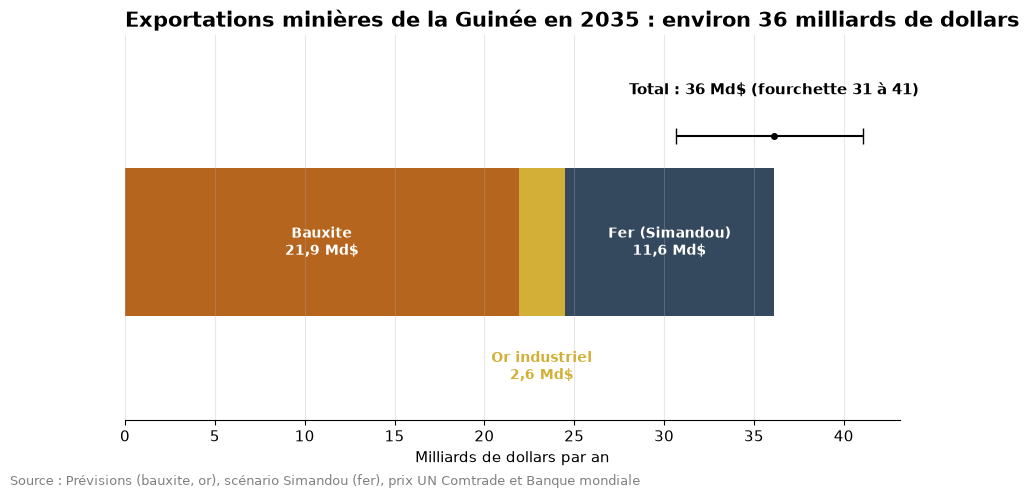

In [6]:
requete("05_prix_reference").show(max_width=200)

simandou = requete("04_scenarios_exportations").df()
fer_2035 = simandou[simandou["annee"] == 2030].set_index("scenario")["milliards_usd"]   # plein régime atteint en 2030

tableau = synthese(prevision_bauxite[prevision_bauxite["annee"] == 2035].iloc[0],
                   prevision_or[prevision_or["annee"] == 2035].iloc[0],
                   requete("05_prix_reference").df(), fer_2035)
display(tableau.round(1))
graphique_synthese(tableau, 2035)

**Conclusion :** en 2035, avec les prix d'aujourd'hui, les exportations minières de la Guinée atteindraient environ **36 milliards de dollars par an** (31 à 41 milliards) :
- **Bauxite : environ 22 milliards.** Elle reste le premier produit, à condition que la tendance se prolonge.
- **Fer de Simandou : environ 12 milliards.** C'est le changement majeur par rapport à aujourd'hui.
- **Or industriel : environ 2,6 milliards**, sans compter l'orpaillage.

À titre de comparaison, le PIB de la Guinée était de 28 milliards de dollars en 2025.

## 6. Comparer : la Guinée face aux autres producteurs de bauxite

Une prévision seule ne dit pas si 270 Mt, c'est beaucoup. Il faut la comparer au reste du monde.

**Attention aux unités :** pour comparer des pays, on prend une seule source, l'USGS, en **tonnes sèches** (sans l'humidité du minerai). Les chiffres de la Guinée sont donc un peu différents de ceux du ministère utilisés plus haut, qui comptent le minerai humide ou exporté (150 Mt sèches contre environ 183 Mt exportées en 2025).

,annee,guinee,australie,chine,monde,part_guinee_pct,rang_guinee
0,2000,15.7,53.8,9.0,136.0,11.5,2
1,2001,15.1,53.8,9.8,137.0,11.0,2
2,2002,15.7,54.1,12.0,144.0,10.9,2
3,2003,16.0,55.6,13.0,155.0,10.3,2
4,2004,16.0,56.6,15.0,159.0,10.1,2
5,2005,16.8,60.0,22.0,178.0,9.4,3
6,2006,18.8,61.8,27.0,193.0,9.7,3
7,2007,18.5,62.4,30.0,204.0,9.1,3
8,2008,18.4,61.4,35.0,211.0,8.7,3
9,2009,13.6,65.2,40.0,209.0,6.5,3


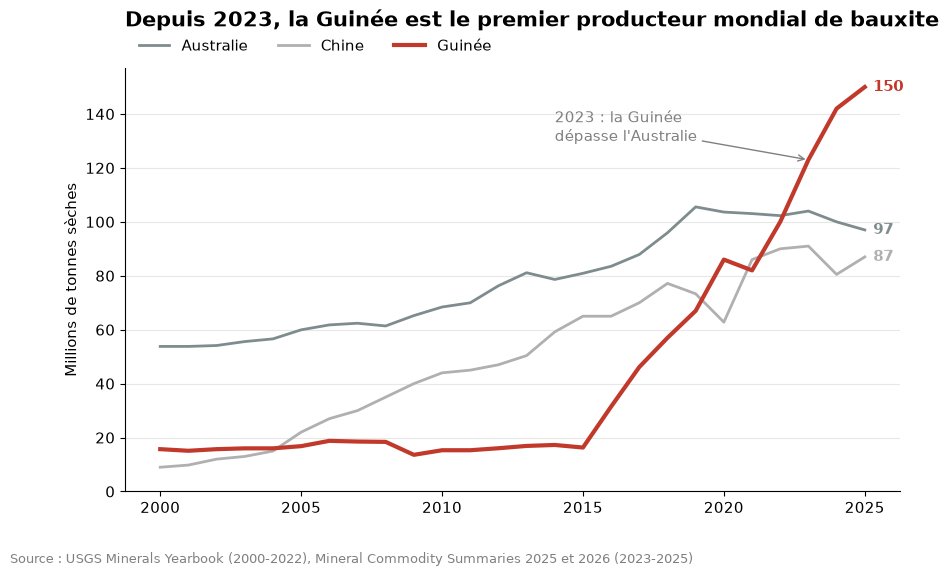

In [7]:
pays = requete("05_bauxite_pays").df()
display(pays.round(1))
graphique_bauxite_pays(pays)

**Constat :**
- En 2015, la Guinée produisait **5 fois moins** que l'Australie (16 Mt contre 81 Mt). Elle était 3e, derrière l'Australie et la Chine.
- En 2023, elle **dépasse l'Australie** et devient le premier producteur mondial (123 Mt contre 104 Mt).
- En 2025, elle produit **150 Mt**, soit plus que l'Australie (97 Mt) et la Chine (87 Mt). L'Australie et la Chine stagnent ou baissent depuis 2019.

In [8]:
requete("05_contribution_hausse_mondiale", debut=2015, fin=2025).df()

,pays,hausse_mt,part_de_la_hausse_pct
0,Monde,142.00,100.0
1,Guinée,133.70,94.0
2,Chine,22.00,15.0
3,Australie,16.09,11.0


**Constat :** entre 2015 et 2025, la production mondiale a augmenté de 142 Mt. La Guinée en a fourni **134 Mt, soit 94 %** de la hausse. Les parts dépassent 100 % au total, car d'autres pays ont reculé (surtout l'Indonésie, qui a interdit l'exportation de bauxite brute en juin 2023 : environ 30 Mt en 2023, 10 Mt en 2025 selon l'USGS).

Autrement dit, **presque toute la bauxite supplémentaire consommée dans le monde depuis 10 ans vient de Guinée**, et elle part en Chine (étape 3).

Guinée : +13.1 Mt par an ; monde : +17.5 Mt par an


,annee,part_pct
0,2026,34.1
1,2027,35.6
2,2028,36.9
3,2029,38.2
4,2030,39.4
5,2031,40.5
6,2032,41.5
7,2033,42.5
8,2034,43.4
9,2035,44.3


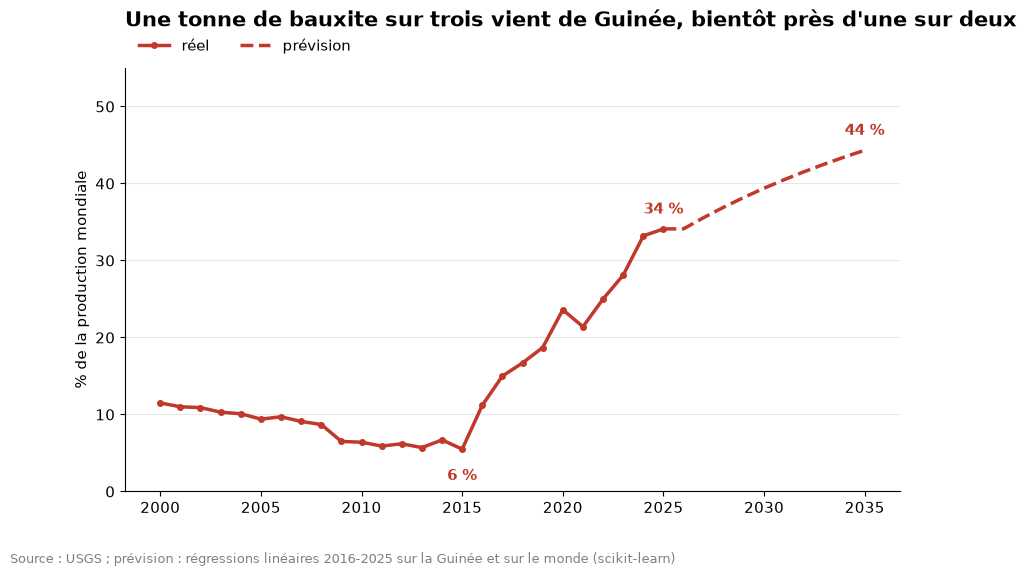

In [9]:
guinee = requete("05_bauxite_monde_serie", pays="Guinée").df()
monde = requete("05_bauxite_monde_serie", pays="Monde").df()
prevision_guinee, modele_guinee = prevoir(guinee, debut=2016, fin=2025, horizon=2035)
prevision_monde, modele_monde = prevoir(monde, debut=2016, fin=2025, horizon=2035)
print(f"Guinée : +{modele_guinee.coef_[0]:.1f} Mt par an ; monde : +{modele_monde.coef_[0]:.1f} Mt par an")

part = part_prevue(prevision_guinee, prevision_monde)
display(part.round(1))
graphique_part_guinee(pays, part)

**Conclusion :** on applique le même modèle à la Guinée et au monde, sur 2016-2025.
- La Guinée ajoute environ **13 Mt par an**, le monde environ **18 Mt par an** : la Guinée fait à elle seule les trois quarts de la croissance mondiale.
- Sa part passerait de **6 % en 2015** à **34 % en 2025**, puis à environ **44 % en 2035**, presque une tonne de bauxite sur deux.

**Ce que ça veut dire :** la Guinée devient **incontournable** pour l'aluminium mondial, ce qui lui donne un pouvoir de négociation (taxes, obligation de raffiner sur place). Mais c'est aussi un **risque** : un seul client, la Chine, et un seul produit. Si la demande chinoise baisse, c'est la Guinée qui encaisse le choc.

## Ce qu'il faut retenir

1. **Regarder avant de modéliser :** la bauxite change de régime en 2016. Une droite sur toute la période se trompait de 39 à 51 % ; une droite sur 2016-2024, de 0 à 11 %.
2. **Tester sur des données cachées :** c'est le test 2022-2024 qui a permis de choisir le modèle, pas l'impression visuelle.
3. **Bauxite en 2035 : environ 270 Mt** (241 à 300), et probablement plus, car la production accélère.
4. **Or : pas de tendance.** Le modèle ne fait pas mieux qu'une moyenne, et c'est une information utile.
5. **Exportations minières en 2035 : environ 36 milliards de dollars par an**, dont un tiers pour Simandou.
6. **Face au monde :** premier producteur de bauxite depuis 2023, 94 % de la hausse mondiale depuis 2015, et environ 44 % de la production mondiale en 2035 si les tendances se prolongent.

## Limites

- **Un modèle linéaire ne connaît que le passé.** Il ne voit ni les capacités maximales des mines, ni la demande chinoise, ni les décisions politiques.
- **Peu de données :** 9 points pour la bauxite depuis 2016, 17 pour l'or. Les intervalles le reflètent.
- **Les prix sont fixés aux niveaux actuels.** Leur variation pèse autant que celle des volumes (voir l'étape 4).
- **Sources raccordées :** USGS jusqu'en 2018, ministère ensuite. Elles concordent à 5 % près sur 2019.
- **Comparaison internationale en tonnes sèches (USGS)**, pas en tonnes du ministère. Les valeurs 2025 sont des estimations de l'USGS, et l'USGS révise souvent les années récentes (Chine 2024 : 93 Mt dans l'édition 2025, 80,5 Mt dans l'édition 2026). On prend toujours l'édition la plus récente.